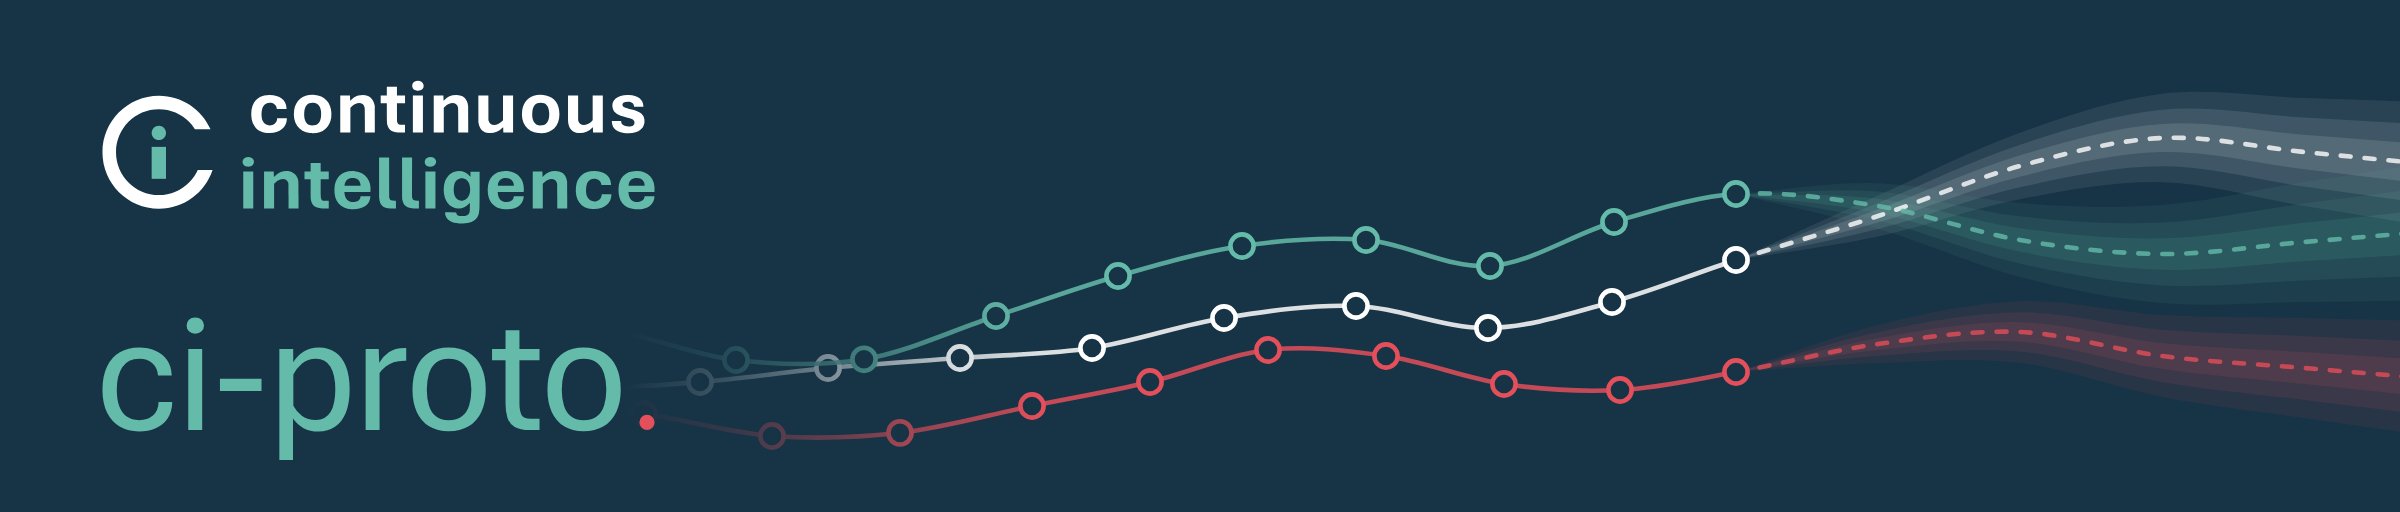

In this notebook, we’ll use ci-proto to forecast bike rentals. We’ll add calendar covariates
to improve the forecasts, explore their uncertainty, and see how the model handles missing data.

Run the cells in order, as later examples reuse the model, data and helpers from earlier ones.


In [ ]:
# In a fresh environment, install the package and the libraries this notebook uses:
# %pip install continuousintelligence matplotlib scikit-learn pyarrow

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

import continuousintelligence as ci

warnings.filterwarnings("ignore", message=".*symlinks.*")  # Hugging Face cache notice on Windows
warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm without ipywidgets
warnings.filterwarnings("ignore", message="Mismatch dtype between input and weight")  # CPU bfloat16
CI_NAVY = "#173446"
CI_TEXT = "#FAFBFB"
CI_MUTED = "#96A3A9"
CI_TEAL = "#65BBAA"
CI_HIGHLIGHT = "#E34F5A"
CI_LINE = "#324C5C"  # 12% CI_TEXT over CI_NAVY

plt.rcParams.update(
    {
        "figure.figsize": (12, 3.6),
        "figure.dpi": 150,
        "savefig.dpi": 600,
        "figure.facecolor": CI_NAVY,
        "axes.facecolor": CI_NAVY,
        "savefig.facecolor": CI_NAVY,
        "text.color": CI_TEXT,
        "axes.labelcolor": CI_TEXT,
        "axes.titlecolor": CI_TEXT,
        "axes.edgecolor": CI_LINE,
        "xtick.color": CI_MUTED,
        "ytick.color": CI_MUTED,
        "grid.color": CI_LINE,
        "legend.labelcolor": CI_TEXT,
        "axes.prop_cycle": plt.cycler(
            color=[
                CI_TEAL,
                CI_HIGHLIGHT,
                CI_TEXT,
                CI_MUTED,
                "#A3D6CC",
                "#EE959C",
                "#3E786F",
                "#AC3D4A",
            ]
        ),
        "axes.spines.top": True,
        "axes.spines.right": True,
        "axes.grid": False,
        "grid.alpha": 1.0,
        "legend.frameon": False,
    }
)

## Load the model

`ci.load_model` downloads the weights and calibration settings from the
Hugging Face Hub on first use, then reuses the local cache. `device="auto"` picks a CUDA GPU when
one is available and falls back to CPU.

In [ ]:
model = ci.load_model("ContinuousIntelligence/ci-proto", device="auto")
levels = model.quantiles  # the probability level of each output quantile

print(f"{len(levels)} quantile levels: {levels[0]:.2f}, {levels[1]:.2f}, …, {levels[-1]:.2f}")

A few helpers keep the rest of the notebook short:

- `qi(level)` finds the index of a quantile level, such as `0.9`.
- `scores` reports three accuracy measures for one forecast:
  - **MAE**: mean absolute error of the median forecast, in the target's own units.
  - **WQL**: weighted quantile loss over all 9 quantiles, a single number for probabilistic accuracy. Lower is better.
  - **80% coverage**: the share of actual values that fall inside the 10–90% band. A calibrated forecast is close to 0.8.
- `plot_forecast` draws history, the 10–90% and 25–75% bands, the median and the actual values.

In [ ]:
def qi(level: float) -> int:
    # Index of the quantile level closest to `level`.
    return int((levels - level).abs().argmin())


def scores(prediction: torch.Tensor, truth) -> dict[str, float]:
    # Accuracy of one series' forecast: prediction [quantiles, horizon], truth [horizon].
    truth = torch.tensor(np.array(truth, dtype=np.float32))
    seen = ~torch.isnan(truth)
    prediction, truth = prediction[:, seen], truth[seen]
    error = truth - prediction
    pinball = torch.maximum(levels[:, None] * error, (levels[:, None] - 1) * error)
    inside = (truth >= prediction[qi(0.1)]) & (truth <= prediction[qi(0.9)])
    return {
        "MAE": (truth - prediction[qi(0.5)]).abs().mean().item(),
        "WQL": (2 * pinball.sum(1).mean() / truth.abs().sum()).item(),
        "80% coverage": inside.float().mean().item(),
    }


def plot_forecast(
    ax, past, prediction, future_index, truth=None, color=CI_TEAL, label="Median", bands=True
):
    # past: Series of recent history; prediction: [quantiles, horizon] for one series.
    if past is not None:
        ax.plot(past.index, past.to_numpy(), color=CI_MUTED, lw=1, label="History")
    for low, high, alpha in ((0.1, 0.9, 0.18), (0.25, 0.75, 0.32)) if bands else ():
        ax.fill_between(
            future_index,
            prediction[qi(low)],
            prediction[qi(high)],
            color=color,
            alpha=alpha,
            lw=0,
            label=f"{low:.0%}–{high:.0%}",
        )
    ax.plot(future_index, prediction[qi(0.5)], color=color, lw=1.6, label=label)
    if truth is not None:
        ax.plot(future_index, np.asarray(truth), color=CI_TEXT, lw=1, ls="--", label="Actual")
    ax.legend(loc="upper left", ncol=5, fontsize=8)

## The data: hourly bike rentals

The OpenML copy of the UCI Bike Sharing dataset has one row per hour, with the rental `count`, the
weather (`temp`, `feel_temp`, `humidity`, `windspeed`, and a `weather` category) and calendar flags
(`holiday`, `workingday`).

In [ ]:
from sklearn.datasets import fetch_openml

# parser="liac-arff" avoids an incompatibility between scikit-learn's default parser and pandas 3.
raw = fetch_openml(data_id=42712, as_frame=True, parser="liac-arff").frame
raw.head()

This copy has no date column, so we rebuild it. Some hours are missing from the source data. We put
the data on a complete hourly grid, filling the missing hours with `NaN`, which the model accepts as
"not observed".

In [ ]:
day = np.r_[0, np.diff(raw["weekday"].to_numpy()) % 7].cumsum()
observed_at = (
    pd.Timestamp("2011-01-01")
    + pd.to_timedelta(day, unit="D")
    + pd.to_timedelta(raw["hour"].to_numpy(), unit="h")
)
assert (observed_at.month == raw["month"].to_numpy()).all()
assert (observed_at.year - 2011 == raw["year"].to_numpy()).all()

grid = pd.date_range(observed_at[0], observed_at[-1], freq="h")
bikes = raw.set_index(observed_at).reindex(grid)

# Calendar facts are known for every hour, including the missing ones, so rebuild them from dates.
holiday_dates = observed_at[(raw["holiday"] == "True").to_numpy()].normalize().unique()
bikes["holiday"] = grid.normalize().isin(holiday_dates).astype(float)
bikes["workingday"] = ((grid.day_of_week < 5) & (bikes["holiday"] == 0)).astype(float)
workingday = (raw["workingday"] == "True").to_numpy()
assert (bikes.loc[observed_at, "workingday"].to_numpy() == workingday).all()

# Categorical inputs are passed as numeric codes.
weather_codes = {"clear": 0, "misty": 1, "rain": 2, "heavy_rain": 3}
bikes["weather"] = bikes["weather"].astype(object).map(weather_codes).astype(float)

print(
    f"{len(grid):,} hours from {grid[0]:%d %b %Y} to {grid[-1]:%d %b %Y}; "
    f"{bikes['count'].isna().sum()} hours missing"
)

In [ ]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(12, 6))
bikes["count"].resample("D").sum().plot(ax=top, lw=0.8, color=CI_TEAL)
top.set(
    title="Daily rentals: growth, yearly seasonality and weather shocks",
    xlabel="",
    ylabel="rentals/day",
)
week = bikes.loc["2012-06-04":"2012-06-10", "count"]
week.plot(ax=bottom, lw=1, color=CI_TEAL)
bottom.set(
    title="One week, hourly: commuter peaks on weekdays, a single midday hump at weekends",
    xlabel="",
    ylabel="rentals/hour",
)
fig.tight_layout()
plt.show()

We forecast the week starting **Sunday 1 July 2012**, one week of hourly steps (`H = 168`).
The week contains the **4 July** public holiday, a Wednesday, when the
weekday commuting peaks disappear.

All earlier data is history. `history` is a `[variables, time]` tensor, so a single series has one
row. The actual values for the forecast week are used only for scoring.

In [ ]:
ORIGIN = pd.Timestamp("2012-07-01")
H = 168
past = bikes[bikes.index < ORIGIN]
future = bikes[bikes.index >= ORIGIN].iloc[:H]
truth = future["count"].to_numpy()

history = torch.tensor(past["count"].to_numpy(), dtype=torch.float32)[None]  # [1, T]
print(f"history: {tuple(history.shape)} ({history.shape[1] / 24:.0f} days)")

## 1. A first forecast from history alone

`model.forecast(history, horizon)` returns a `[variables, quantiles, horizon]` tensor: 9 quantiles
for each future hour, in the original units.

In [ ]:
plain = model.forecast(history, horizon=H)
print(f"forecast: {tuple(plain.shape)}")

fig, ax = plt.subplots()
plot_forecast(ax, past["count"].iloc[-7 * 24 :], plain[0], future.index, truth)
ax.set(title="History only: one week ahead", ylabel="rentals/hour")
pd.DataFrame({"history only": scores(plain[0], truth)}).T.round(3)

Without any extra inputs, the model picks up the daily and weekly shape from history.
It expects commuter peaks on 4 July, though, because it has no way of knowing it is a holiday.

## 2. Covariates: known-future inputs

Covariates are extra inputs that the model conditions on. It doesn't forecast them.
Pass values known in advance for the forecast week with `future_covariates`, shaped
`[known, T + H]`.

We compare two ways to describe the calendar:

1. **Calendar flags.** `holiday` and `workingday` are known for the forecast week.
2. **A categorical day type × hour code.** Categorical rows hold numeric codes and are listed in
   `categorical_future`. The model replaces each code with statistics of the
   target for that category, computed from the history. 


In [ ]:
def rows(frame: pd.DataFrame, columns: list[str]) -> torch.Tensor:
    # Covariate tensor [len(columns), len(frame)] from DataFrame columns.
    return torch.tensor(frame[columns].to_numpy().T, dtype=torch.float32)


window = pd.concat([past, future])  # history plus the forecast week: [T + H] rows
window["daytype_hour"] = window.index.hour + 24 * window["workingday"]  # 48 categories

flags = model.forecast(
    history, horizon=H, future_covariates=rows(window, ["holiday", "workingday"])
)
daytype = model.forecast(
    history,
    horizon=H,
    future_covariates=rows(window, ["daytype_hour"]),
    categorical_future=(0,),
)

In [ ]:
# A simple benchmark: repeat last week's value at the same hour.
seasonal_naive = past["count"].iloc[-H:].to_numpy()

results = pd.DataFrame(
    {
        "seasonal naive (last week)": {"MAE": np.nanmean(np.abs(truth - seasonal_naive))},
        "history only": scores(plain[0], truth),
        "+ holiday & working-day flags": scores(flags[0], truth),
        "+ day type × hour (categorical)": scores(daytype[0], truth),
    }
).T

fig, ax = plt.subplots(figsize=(12, 4))
days = (future.index >= "2012-07-03") & (future.index < "2012-07-06")
plot_forecast(
    ax,
    None,
    plain[0][:, days],
    future.index[days],
    color=CI_MUTED,
    label="history only",
    bands=False,
)
plot_forecast(
    ax,
    None,
    daytype[0][:, days],
    future.index[days],
    truth[days],
    color=CI_TEAL,
    label="+ day type × hour",
)
ax.axvspan(
    pd.Timestamp("2012-07-04"),
    pd.Timestamp("2012-07-05"),
    color=CI_HIGHLIGHT,
    alpha=0.18,
    label="4 July public holiday",
)
ax.set(title="3–5 July, with 4 July shaded", ylabel="rentals/hour")
ax.legend(
    loc="lower left",
    bbox_to_anchor=(0, 1.12, 1, 0),
    mode="expand",
    ncol=6,
    fontsize=8,
    borderaxespad=0,
)
fig.tight_layout()
results.round(3)

The calendar flags help, and the categorical day-type code helps much more. With it, the model
drops the commuter peaks on 4 July and forecasts a weekend-like day instead. Holidays are rare in
the history, about one a month, so handing the model a target-encoded category is more effective
than a bare 0/1 flag.

## 3. Using the quantiles

The 9 quantiles describe a full predictive distribution for every hour, which supports several
practical uses:

- **Intervals** for planning ranges, such as the 20–80% band.
- **Exceedance probabilities**, such as the chance that demand exceeds a capacity. We read them off
  the quantiles by interpolation.
- **Calibration checks**: a nominal 80% interval should contain about 80% of the actual values.

In [ ]:
peak = pd.Timestamp("2012-07-02 17:00")  # Monday evening rush hour
step = future.index.get_loc(peak)
summary = {
    f"P{round(level * 100)}": plain[0, qi(level), step].item()
    for level in (0.1, 0.3, 0.5, 0.7, 0.9)
}
print(f"{peak:%a %d %b %H:%M}: actual {truth[step]:.0f} rentals")
pd.Series(summary, name="forecast").to_frame().T

In [ ]:
CAPACITY = 600  # an illustrative threshold, e.g. bikes available at docks across the network


def exceedance(prediction_row: torch.Tensor, threshold: float) -> np.ndarray:
    # P(value > threshold) for each step, interpolated from the quantiles [quantiles, horizon].
    values = prediction_row.numpy()
    cdf = [
        np.interp(threshold, values[:, h], levels.numpy(), left=0.0, right=1.0)
        for h in range(values.shape[1])
    ]
    return 1 - np.array(cdf)


fig, ax = plt.subplots()
ax.bar(future.index, exceedance(plain[0], CAPACITY), width=1 / 24, color=CI_HIGHLIGHT)
ax.set(
    title=f"Probability that hourly demand exceeds {CAPACITY} rentals",
    ylabel="probability",
    ylim=(0, 1),
)
plt.show()

In [ ]:
rows = {}
for low, high in ((0.3, 0.7), (0.1, 0.9)):
    inside = (truth >= plain[0, qi(low)].numpy()) & (truth <= plain[0, qi(high)].numpy())
    rows[f"{high - low:.0%} interval"] = {
        "nominal": high - low,
        "observed this week": inside.mean(),
    }
pd.DataFrame(rows).T.round(2)

## 4. Missing data

Real data has gaps. Mark missing observations as `NaN` in `history` (or any covariate), with no need
to impute. The history used so far already contains the dataset's own missing hours. Here we make it
much harder: we delete a random 30% of hours **and** add a three-day outage that ends two days
before the forecast origin.

In [ ]:
generator = torch.Generator().manual_seed(0)
gappy = history.clone()
gappy[torch.rand(gappy.shape, generator=generator) < 0.3] = torch.nan
gappy[:, -5 * 24 : -2 * 24] = torch.nan
print(f"observed: {(~gappy.isnan()).float().mean():.0%} of hours")

degraded = model.forecast(gappy, horizon=H)

fig, ax = plt.subplots()
plot_forecast(
    ax,
    pd.Series(gappy[0, -7 * 24 :].numpy(), past.index[-7 * 24 :]),
    degraded[0],
    future.index,
    truth,
)
ax.set(
    title="Forecasting through gaps: 30% of hours removed plus a three-day outage",
    ylabel="rentals/hour",
)
pd.DataFrame(
    {"complete history": scores(plain[0], truth), "with gaps": scores(degraded[0], truth)}
).T.round(3)

<h2 style="color: #173446;">Data sources and licences</h2>

This tutorial uses the following data sources:

**Bike Sharing.** From
<a href="https://doi.org/10.24432/C5W894" style="color: #173446; text-decoration: underline; text-decoration-color: #65BBAA;">Hadi Fanaee-T (2013), <em>Bike Sharing</em>, UCI Machine Learning Repository</a>,
accessed through <a href="https://www.openml.org/d/42712" style="color: #173446; text-decoration: underline; text-decoration-color: #65BBAA;">OpenML dataset 42712</a>.
Licensed under <a href="https://creativecommons.org/licenses/by/4.0/" style="color: #173446; text-decoration: underline; text-decoration-color: #65BBAA;">CC BY 4.0</a>.
We reconstruct timestamps, reindex missing hours, encode categories, aggregate some plots and introduce
artificial gaps for demonstration.
